作业3：NumPy、Matplotlib 与 pandas

In [3]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080116
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] D:\conda\conda_envs\myenv1
[学号] 20244080116
[机器指纹] 5ec80ac0c8f60ff8
[RUN_ID] 20244080116-5ec80ac0c8f60ff8


围绕半圆定律

随机矩阵理论研究随机矩阵的性质。对于下述随机对称矩阵，随着矩阵阶数 n 增⼤，其特征值的分布趋近于半圆定律。半圆密度为
$$
f(x)=
\begin{cases}
\displaystyle \frac{1}{2\pi}\sqrt{4-x^2}, & |x|\le 2, \\[4pt]
0, & |x|>2.
\end{cases}
$$
构造 $n × n $的对称随机矩阵 Z：对所有 $1 ≤ i ≤ j ≤ n$，独⽴地从均值为 0、⽅差为$1/n$ 的正态分布抽取 $Z_{ij}$，再令 $Z_{ji}=Z_{ij}$。这样的矩阵称为 Wigner 矩阵。其特征值
的标准化直⽅图会随 n 增⼤⽽逐渐接近上述密度曲线。

1. 编写 wigner_density(x)，接收⼀个整数或浮点数，返回半圆密度在 x 处的
值，返回值为浮点数。不需要检查输⼊类型；函数应同时适⽤于 Python 和 NumPy
的整数、浮点数。计算平⽅根时使⽤ numpy.sqrt，不要使⽤ math.sqrt。

2. 编写 generate_wigner(n)，接收正整数 n，返回⼀个随机⽣成的 n × n
Wigner 矩阵，可以使⽤ NumPy 的⼆维数组或矩阵表⽰。若输⼊不是整数或不是正
数，应抛出合适的异常。

3. 编写 get_spectrum(matrix)，接收 NumPy 矩阵或⼆维 NumPy 数组，返回包
含其全部特征值的 NumPy 数组，按⾮递减顺序排列。本函数不需要检查输⼊类
型。

4. 画⼀张包含四个纵向排列⼦图的图。对 n = 100, 200, 500, 1000，每个⼦图分别
⽤蓝⾊、标准化的直⽅图展⽰随机 n × n Wigner 矩阵的特征值，并叠加红⾊的半
圆密度曲线。根据图形说明：n ⼤约达到多少时，半圆密度能较好地拟合特征值分
布？使⽤ Kolmogorov–Smirnov 检验作更严格的⽐较是可选任务。特征值计算可能
较慢，尤其是远⼤于 1000 阶的矩阵。

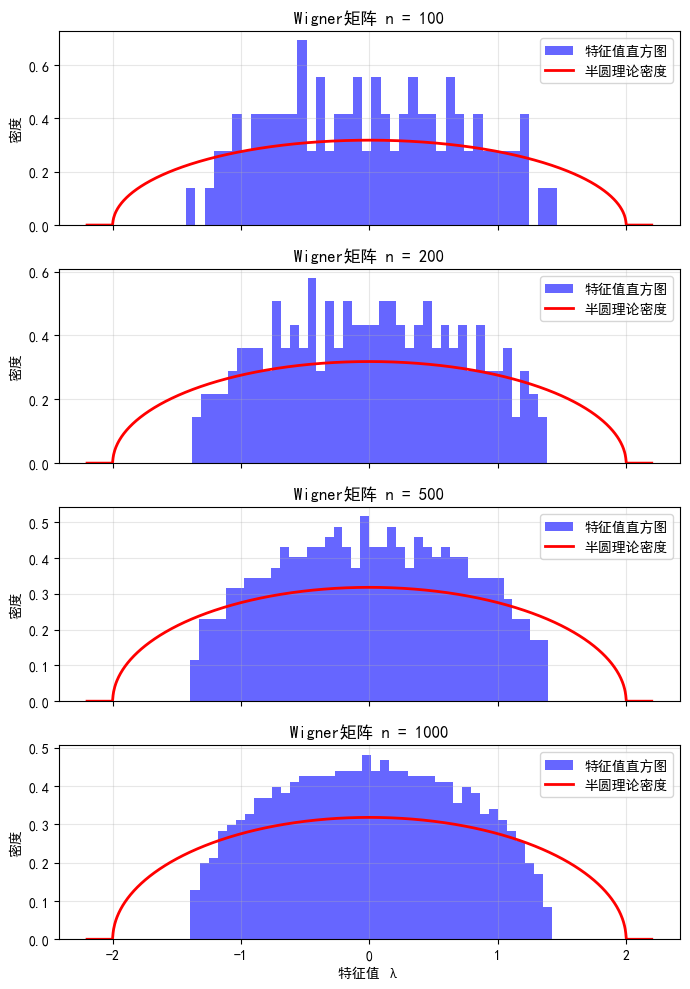

In [7]:
import numpy as np
import warnings
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

warnings.filterwarnings("ignore")

# ========== 任务1：wigner_density(x) 半圆密度函数 ==========
def wigner_density(x):
    """
    半圆律密度函数
    f(x) = 1/(2π) * sqrt(4-x²), |x| ≤2 ; else 0
    支持标量和numpy数组输入，只用np.sqrt
    """
    x = np.asarray(x)
    res = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    res[mask] = 1.0 / (2 * np.pi) * np.sqrt(4 - x[mask]**2)
    return res

# ========== 任务2：generate_wigner(n) 生成Wigner对称矩阵 ==========
def generate_wigner(n):
    """
    构造n阶Wigner对称矩阵
    对1 ≤ i ≤ j ≤ n，Z_ij ~ N(0, 1/n)，Z_ji = Z_ij
    输入非法抛出异常
    """
    if not isinstance(n, int):
        raise TypeError("n必须是整数")
    if n <= 0:
        raise ValueError("n必须是正整数")
    sigma = np.sqrt(1.0 / n)
    mat = np.random.normal(loc=0, scale=sigma, size=(n, n))
    mat = (mat + mat.T) / 2   # 强制对称，满足 Z_ji = Z_ij
    return mat

# ========== 任务3：get_spectrum(matrix) 获取排序后的特征值 ==========
def get_spectrum(matrix):
    """
    实对称矩阵求全部特征值，按非递减顺序返回numpy数组
    eigvalsh专门用于对称/厄米矩阵，返回值默认升序
    """
    eigvals = np.linalg.eigvalsh(matrix)
    return eigvals

# ========== 任务4：绘图：4个子图纵向排列 n=100,200,500,1000 ==========
def plot_semicircle_comparison():
    n_list = [100, 200, 500, 1000]
    fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(7, 10), sharex=True)
    x_curve = np.linspace(-2.2, 2.2, 1000)
    y_curve = wigner_density(x_curve)

    for ax, n in zip(axes, n_list):
        W = generate_wigner(n)
        eig = get_spectrum(W)
        # 蓝色标准化直方图 density=True：面积积分=1，和概率密度对齐
        ax.hist(eig, bins=40, density=True, color="blue", alpha=0.6, label="特征值直方图")
        # 红色理论半圆密度曲线
        ax.plot(x_curve, y_curve, color="red", lw=2, label="半圆理论密度")
        ax.set_title(f"Wigner矩阵 n = {n}")
        ax.set_ylabel("密度")
        ax.legend()
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("特征值 λ")
    plt.tight_layout()
    plt.show()

# 运行主绘图
if __name__ == "__main__":
    plot_semicircle_comparison()


Conway 的⽣命游戏

⽣命游戏在⼀个 m × n 棋盘上进⾏，棋盘⽤ NumPy 的⼆维数组表⽰：活细胞记为 1，死细胞记为 0。每⼀步按以下规则同时更新所有细胞：

- 活细胞有少于两个活邻居时死亡；
- 活细胞有两个或三个活邻居时继续存活；
- 活细胞有多于三个活邻居时死亡；
- 死细胞恰好有三个活邻居时复活；
- 其他死细胞保持死亡。

每个细胞有上、下、左、右和四个对⻆⽅向的邻居，共⼋个。棋盘采⽤环绕边界：例
如，位置 (0, 0) 上⽅的邻居是 (m-1, 0)，位置 (m-1, n-1) 右侧的邻居是 (m-1,
0)。

1. 编写 is_valid_board(board)，接收⼀个 NumPy ndarray，若它是有效的⽣
命游戏棋盘（⼆维、元素仅为 0 或 1）则返回 Python 布尔值 True，否则返回
False。

2. 编写 gol_step(board)，接收⼀个 m × n 棋盘，返回同样⼤⼩的 NumPy 数
组，表⽰下⼀步的棋盘。函数应先检查输⼊是否为有效棋盘，⽆效时抛出合适的异
常。计算某个细胞的下⼀状态时，应使⽤原棋盘中的邻居状态。

3. 编写 draw_gol_board(board)，将棋盘画成 m × n 个⽅格：活细胞为⿊⾊，
死细胞为⽩⾊。图中不显⽰⽹格线、轴标签或轴刻度。可以使⽤
plt.xticks()、plt.yticks() 和 plt.get_cmap() 等函数。

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 1. is_valid_board(board) ==========
def is_valid_board(board):
    """
    判断是否是合法生命游戏棋盘：二维ndarray，元素只有0或1
    """
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    # 所有元素必须是0或者1
    return np.all(np.isin(board, [0, 1]))


# ========== 2. gol_step(board) 环绕(环形/toroidal)边界 ==========
def gol_step(board):
    """
    输入棋盘，返回下一步棋盘；先校验合法性，非法抛异常
    环绕边界，使用np.roll实现周期平移，基于原棋盘统计邻居
    """
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    old = board.copy()
    # 8个方向滚动求和，wrap环绕
    neighbor_count = (
        np.roll(old, (1, 0), axis=(0, 1)) +
        np.roll(old, (-1, 0), axis=(0, 1)) +
        np.roll(old, (0, 1), axis=(0, 1)) +
        np.roll(old, (0, -1), axis=(0, 1)) +
        np.roll(old, (1, 1), axis=(0, 1)) +
        np.roll(old, (1, -1), axis=(0, 1)) +
        np.roll(old, (-1, 1), axis=(0, 1)) +
        np.roll(old, (-1, -1), axis=(0, 1))
    )
    new = np.zeros_like(old, dtype=int)
    # 规则：
    # 活细胞(1)：邻居2、3存活；<2 或 >3 死亡
    # 死细胞(0)：邻居恰好=3复活，其余保持0
    alive_mask = old == 1
    new[alive_mask & ((neighbor_count == 2) | (neighbor_count == 3))] = 1
    new[(old == 0) & (neighbor_count == 3)] = 1
    return new


# ========== 3. draw_gol_board(board) 绘图函数 ==========
def draw_gol_board(board):
    """
    绘制棋盘：活=黑色，死=白色；无坐标轴、无刻度、无网格线
    使用 binary colormap，符合题目要求
    """
    cmap = plt.get_cmap("binary")
    plt.imshow(board, cmap=cmap, interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()


True


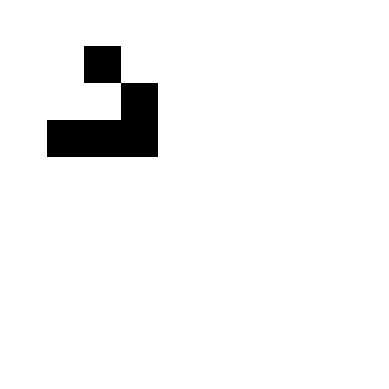

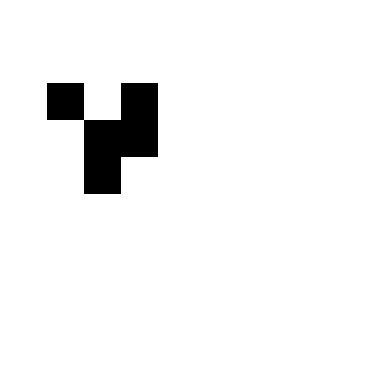

In [12]:
# 构造滑翔机测试
glider = np.array([
    [0,1,0],
    [0,0,1],
    [1,1,1]
])
pad = np.zeros((10,10), dtype=int)
pad[1:4,1:4] = glider

print(is_valid_board(pad))
draw_gol_board(pad)
next_board = gol_step(pad)
draw_gol_board(next_board)

使⽤ pandas DataFrame

本题练习读取、修改和保存 DataFrame，以及按组汇总数据。
1. 下载 iris.csv(www.kaggle.com/datasets/gradylynn/iris-csv)。使⽤ pandas 将它
读⼊为 DataFrame；CSV 的第⼀⾏是列标题。回答：数据集有多少个数据点？每
列是什么数据类型？列名是什么？数据中有多少种花卉？列名对应花卉种类，以及
花瓣⻓度、花瓣宽度、萼⽚⻓度和萼⽚宽度四项测量。

2. 已知数据的第 35 个和第 38 个数据⾏有误（不计列标题）。将第 35 ⾏改为
4.9,3.1,1.5,0.2,"setosa"，其中原⽂件的第四项测量有误；将第 38 ⾏改为
4.9,3.6,1.4,0.1,"setosa"，其中原⽂件的第⼆、三项测量有误。请在
DataFrame 中完成修改，并检查修改后的两⾏。若采⽤从 0 开始的默认⾏索引，
这两⾏的索引分别是 34 和 37。

3. 添加两列新特征：Petal.Ratio 为花瓣⻓度除以花瓣宽度；Sepal.Ratio 为萼
⽚⻓度除以萼⽚宽度。

4. 将更正并扩展后的 DataFrame 保存为 iris_corrected.csv，并随作业提交。

5. 按花卉种类分组，分别计算 Petal.Ratio 和 Sepal.Ratio 的平均值、中位数、
最⼩值、最⼤值和标准差。使⽤合适的 groupby() 或聚合操作⼀次获得这些结
果。

In [3]:
import pandas as pd
import numpy as np

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

FILE = "Iris.csv"
df = pd.read_csv(FILE)   # 第一行自动作为列标题

# 按文件真实表头重命名
df = df.rename(columns={
    "Id": "id",
    "SepalLengthCm": "sepal_length",
    "SepalWidthCm": "sepal_width",
    "PetalLengthCm": "petal_length",
    "PetalWidthCm": "petal_width",
    "Species": "species",
})


df["species"] = df["species"].str.replace("Iris-", "", regex=False)

In [4]:
print("任务 1：数据集基本信息")
print("=" * 70)
print("数据点个数：", len(df))
print("\n每列数据类型：")
print(df.dtypes.to_string())
print("\n列名：", df.columns.tolist())
print("\n花卉种类数：", df["species"].nunique(), "种")
print("各花卉种类及数量：")
print(df["species"].value_counts().to_string())

meaning = {
    "id": "样本编号（行号）",
    "sepal_length": "花萼长度（cm）",
    "sepal_width": "花萼宽度（cm）",
    "petal_length": "花瓣长度（cm）",
    "petal_width": "花瓣宽度（cm）",
    "species": "花卉种类（setosa / versicolor / virginica）",
}
print("\n列名与测量含义对应：")
for col, desc in meaning.items():
    print(f"  {col:<14} -> {desc}")

print("\n前 5 行预览：")
print(df.head().to_string())

任务 1：数据集基本信息
数据点个数： 150

每列数据类型：
id                int64
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object

列名： ['id', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

花卉种类数： 3 种
各花卉种类及数量：
species
setosa        50
versicolor    50
virginica     50

列名与测量含义对应：
  id             -> 样本编号（行号）
  sepal_length   -> 花萼长度（cm）
  sepal_width    -> 花萼宽度（cm）
  petal_length   -> 花瓣长度（cm）
  petal_width    -> 花瓣宽度（cm）
  species        -> 花卉种类（setosa / versicolor / virginica）

前 5 行预览：
   id  sepal_length  sepal_width  petal_length  petal_width species
0   1           5.1          3.5           1.4          0.2  setosa
1   2           4.9          3.0           1.4          0.2  setosa
2   3           4.7          3.2           1.3          0.2  setosa
3   4           4.6          3.1           1.5          0.2  setosa
4   5           5.0          3.6           1.4          0.2  setosa


In [5]:
print("任务 2：数据集描述性统计\n")
print("=" * 70)
print("修改前：")
print(df.loc[[34, 37]].to_string())

# 第 35 行（索引 34）：第四项测量（petal_width）有误 -> 4.9, 3.1, 1.5, 0.2，"setosa"
df.loc[34, ["sepal_length", "sepal_width", "petal_length", "petal_width"]] = [4.9, 3.1, 1.5, 0.2]
df.loc[34, "species"] = "setosa"

# 第 38 行（索引 37）：第二、三项测量（sepal_width、petal_length）有误 -> 4.9, 3.6, 1.4, 0.1，"setosa"
df.loc[37, ["sepal_length", "sepal_width", "petal_length", "petal_width"]] = [4.9, 3.6, 1.4, 0.1]
df.loc[37, "species"] = "setosa"

print("\n修改后（检查两行）：")
print(df.loc[[34, 37]].to_string())

任务 2：数据集描述性统计

修改前：
    id  sepal_length  sepal_width  petal_length  petal_width species
34  35           4.9          3.1           1.5          0.1  setosa
37  38           4.9          3.1           1.5          0.1  setosa

修改后（检查两行）：
    id  sepal_length  sepal_width  petal_length  petal_width species
34  35           4.9          3.1           1.5          0.2  setosa
37  38           4.9          3.6           1.4          0.1  setosa


In [6]:
print("任务 3：添加新列\n添加新列后：")
print("=" * 70)
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]
print(df.head().to_string())

任务 3：添加新列
添加新列后：
   id  sepal_length  sepal_width  petal_length  petal_width species  Petal.Ratio  Sepal.Ratio
0   1           5.1          3.5           1.4          0.2  setosa          7.0     1.457143
1   2           4.9          3.0           1.4          0.2  setosa          7.0     1.633333
2   3           4.7          3.2           1.3          0.2  setosa          6.5     1.468750
3   4           4.6          3.1           1.5          0.2  setosa          7.5     1.483871
4   5           5.0          3.6           1.4          0.2  setosa          7.0     1.388889


In [7]:
print("\n任务 4：保存数据集\n")
print("=" * 70)
df.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv，形状：", df.shape)


任务 4：保存数据集

已保存 iris_corrected.csv，形状： (150, 8)


In [8]:
print("\n任务 5：分组统计\n")
print("=" * 70)
result = df.groupby("species").agg(
    Petal_mean=("Petal.Ratio", "mean"),
    Petal_median=("Petal.Ratio", "median"),
    Petal_min=("Petal.Ratio", "min"),
    Petal_max=("Petal.Ratio", "max"),
    Petal_std=("Petal.Ratio", "std"),
    Sepal_mean=("Sepal.Ratio", "mean"),
    Sepal_median=("Sepal.Ratio", "median"),
    Sepal_min=("Sepal.Ratio", "min"),
    Sepal_max=("Sepal.Ratio", "max"),
    Sepal_std=("Sepal.Ratio", "std"),
)
print(result.round(4).to_string())


任务 5：分组统计

            Petal_mean  Petal_median  Petal_min  Petal_max  Petal_std  Sepal_mean  Sepal_median  Sepal_min  Sepal_max  Sepal_std
species                                                                                                                         
setosa          6.9080        7.0000     2.6667       15.0     2.8545      1.4702        1.4631     1.2683     1.9565     0.1187
versicolor      3.2428        3.2404     2.6667        4.1     0.3125      2.1604        2.1613     1.7647     2.8182     0.2287
virginica       2.7807        2.6667     2.1250        4.0     0.4074      2.2305        2.1695     1.8235     2.9615     0.2470
